# 05 Kiểm chứng độc lập kết quả v1

Hậu kiểm điểm đã lưu; không fit, chọn đặc trưng, ngưỡng hoặc ngân sách mới. Test v1 đã được xem. Chỉ xuất bảng tổng hợp, không công bố dữ liệu cấp bản ghi.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT/'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'src'))
import pandas as pd
from maintenance.review import audit_package, build_review_figures
summary = audit_package(ROOT)
assert summary['status'] == 'PASS'
summary

{'status': 'PASS',
 'scope': 'post-hoc independent recomputation; no fitting or selection',
 'package_tables': 8,
 'metric_groups': 40,
 'budget_groups': 120,
 'platform': 'Windows-11-10.0.26200-SP0',
 'python': '3.12.8',
 'pandas': '3.1.0',
 'numpy': '2.5.4',
 'scikit_learn': '1.9.1',
 'audit_source_sha256': 'e77e9667c77150dc47a1f62940b6e4a4f2f042092f79df543c45cf0507883a76',
 'handoff_manifest_sha256': 'e330e97e0e66e91622d2582d5dbdb191e84fa2559f6088b37c8ce360c61bf951',
 'evaluation_lock_sha256': '6f07b9cadcda87350d116b5e8fd878a81e2374298bab2f56b32c73349bc8ce9a',
 'outputs': {'budgets.csv': '617ef2fd8a8ca86c6ba3436ea12c7b97b5b45d9c4368dd04f411e50ea7faa9e8',
  'group-errors.csv': '9aefc055cdca13e9711b5579ace5846f5c9b309fa78dd0808736416ed1d1d802',
  'metrics.csv': 'bc8608a5826c9fe8abe9eb96f52b6194ddcd4167258054416d5fac9b7888643c',
  'package-checks.csv': 'cdbadb66ac61096c97130216ebf8d9a6d93e5a5b53aece0166535ae64d319f5f',
  'validation-feature-comparison.csv': '212320e97ee213c83729c480ebc

## Kiểm tra tám bảng nguồn
Hash, thứ tự cột, khóa, null; join nhiều-một, quần thể split, thứ hạng và ngưỡng được kiểm tra trước so sánh chỉ số.

In [2]:
pd.read_csv(ROOT/'reports/tables/review/package-checks.csv')

,table,rows,sha256,hash_schema_key_null_checks
0,readings,10000,b32d44590239e9ae625c13a56ba4f8f2514d779e0f1be0...,PASS
1,features,10000,8a92f01f5156284991f1bbb06fbd2880ca7f77a4de86b7...,PASS
2,quality_flags,10000,897ae0de7af67080b8cd7f724e70c1693547c3f636c8bc...,PASS
3,split_membership,20000,11f6ea95126d0309c68492379925c1df7d7d3c2ae45491...,PASS
4,model_runs,20,4fa648e396ae19d0d7afa40e02a38a632ad5df9a0a94a1...,PASS
5,scores,78000,91529df9dd9c4022bfdc1c2222ae498c0b992071d0a619...,PASS
6,metrics,40,df08a9b62b83e7874acb0f2f5b6f33be7eee49fcd57242...,PASS
7,budget_metrics,120,e063ba8606760cceefb4071bd0d3c8d90e3e483d378a7b...,PASS


## Ngân sách cố định trên test chính
Top-k tính trên toàn tập rồi mới giao nhóm. Không lấy top-k riêng trong Type hoặc mode. Always-normal không có chính sách xếp hạng hữu ích.

In [3]:
budgets = pd.read_csv(ROOT/'reports/tables/review/budgets.csv')
main = budgets.loc[budgets.split_id.eq('ordered-gap100-v1') & budgets['split'].eq('test') & budgets.seed.eq(42)]
main[['model_family','budget_k','tp','fp','fn','precision','recall','topk_applicable']]

,model_family,budget_k,tp,fp,fn,precision,recall,topk_applicable
0,always_normal,20,NaN,NaN,NaN,NaN,NaN,False
1,always_normal,50,NaN,NaN,NaN,NaN,NaN,False
2,always_normal,100,NaN,NaN,NaN,NaN,NaN,False
18,isolation_forest,20,8.0,12.0,30.0,0.40,0.210526,True
19,isolation_forest,50,13.0,37.0,25.0,0.26,0.342105,True
20,isolation_forest,100,15.0,85.0,23.0,0.15,0.394737,True
36,logistic_regression,20,15.0,5.0,23.0,0.75,0.394737,True
37,logistic_regression,50,21.0,29.0,17.0,0.42,0.552632,True
38,logistic_regression,100,25.0,75.0,13.0,0.25,0.657895,True
42,random,20,0.0,20.0,38.0,0.00,0.000000,True


## Lỗi theo Type và loại hỏng
Mode có thể chồng lấp; không cộng các hàng mode thành số ca hỏng. Nhóm không có ca hỏng có recall null, không phải 0%.

In [4]:
groups = pd.read_csv(ROOT/'reports/tables/review/group-errors.csv')
groups[['split_id','model_family','group','rows','n_failures','tp','fp','fn','global_top50_hits','global_top50_recall']]

,split_id,model_family,group,rows,n_failures,tp,fp,fn,global_top50_hits,global_top50_recall
0,ordered-gap100-v1,isolation_forest,Type=L,1117,31,7,1,24,7,0.225806
1,ordered-gap100-v1,isolation_forest,Type=M,573,7,6,5,1,6,0.857143
2,ordered-gap100-v1,isolation_forest,Type=H,210,0,0,19,0,0,NaN
3,ordered-gap100-v1,isolation_forest,mode=twf,10,10,2,0,8,2,0.200000
4,ordered-gap100-v1,isolation_forest,mode=hdf,0,0,0,0,0,0,NaN
5,ordered-gap100-v1,isolation_forest,mode=pwf,10,10,7,0,3,7,0.700000
6,ordered-gap100-v1,isolation_forest,mode=osf,20,20,8,0,12,8,0.400000
7,ordered-gap100-v1,isolation_forest,mode=rnf,0,0,0,0,0,0,NaN
8,ordered-gap100-v1,isolation_forest,failure_without_mode,2,2,0,0,2,0,0.000000
9,ordered-gap100-v1,isolation_forest,mode_without_failure,0,0,0,0,0,0,NaN


## Ba hình tổng hợp
Các biến vật lý được so bằng kết quả candidates trên validation đã có, không chọn biến theo test.

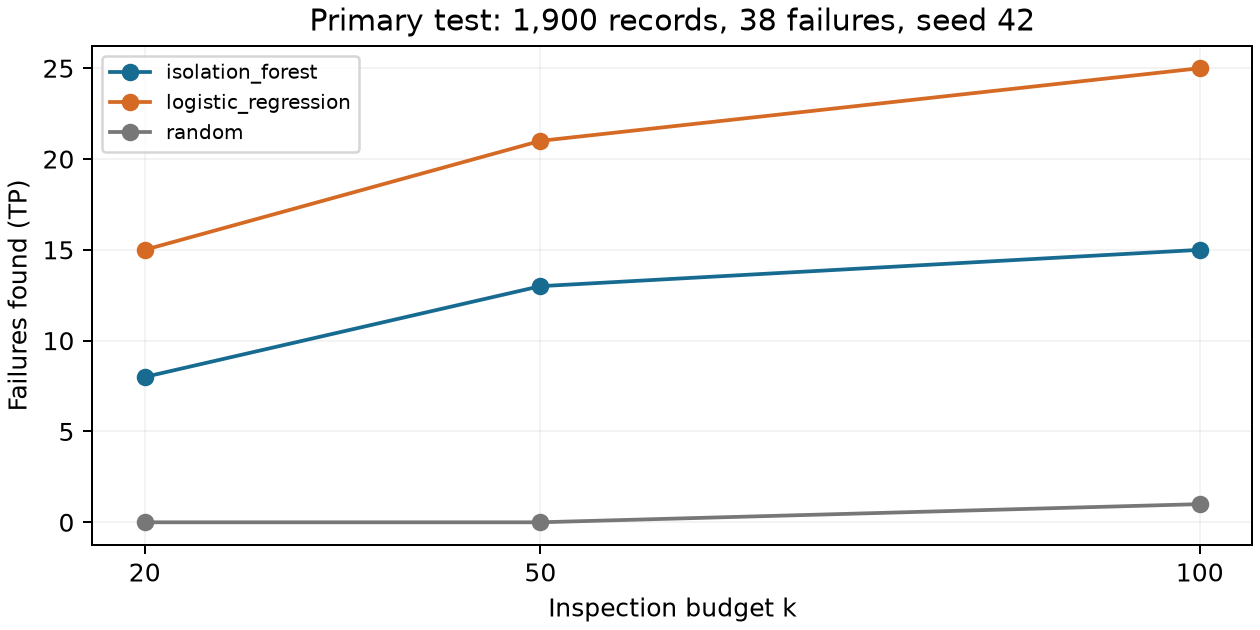

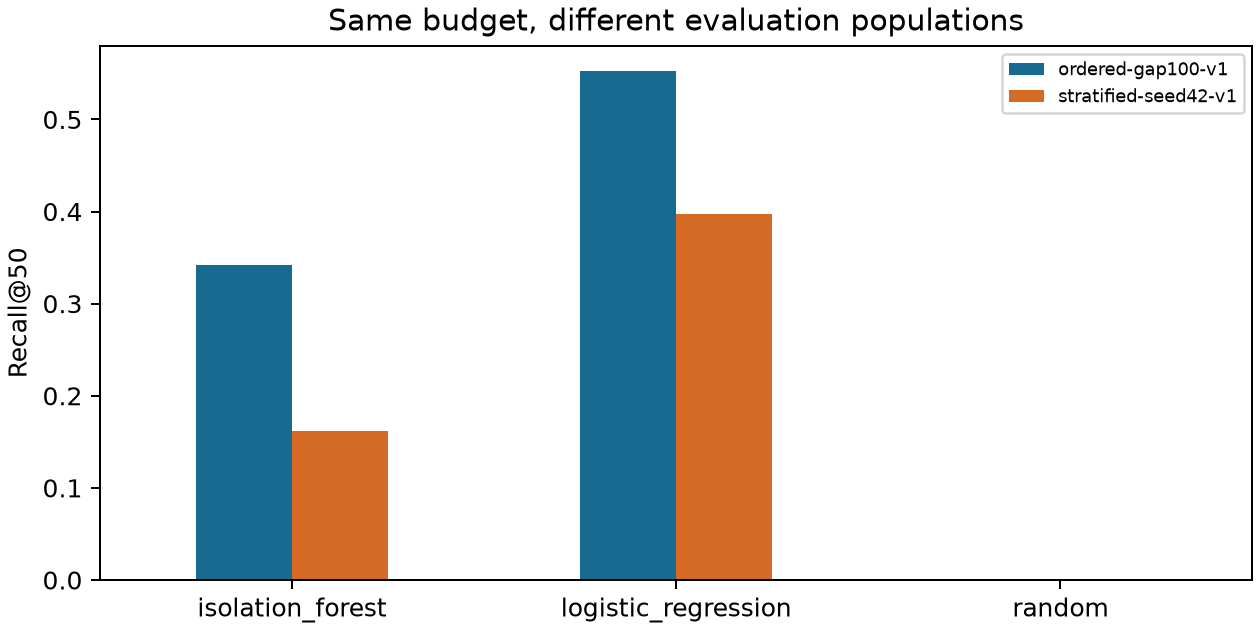

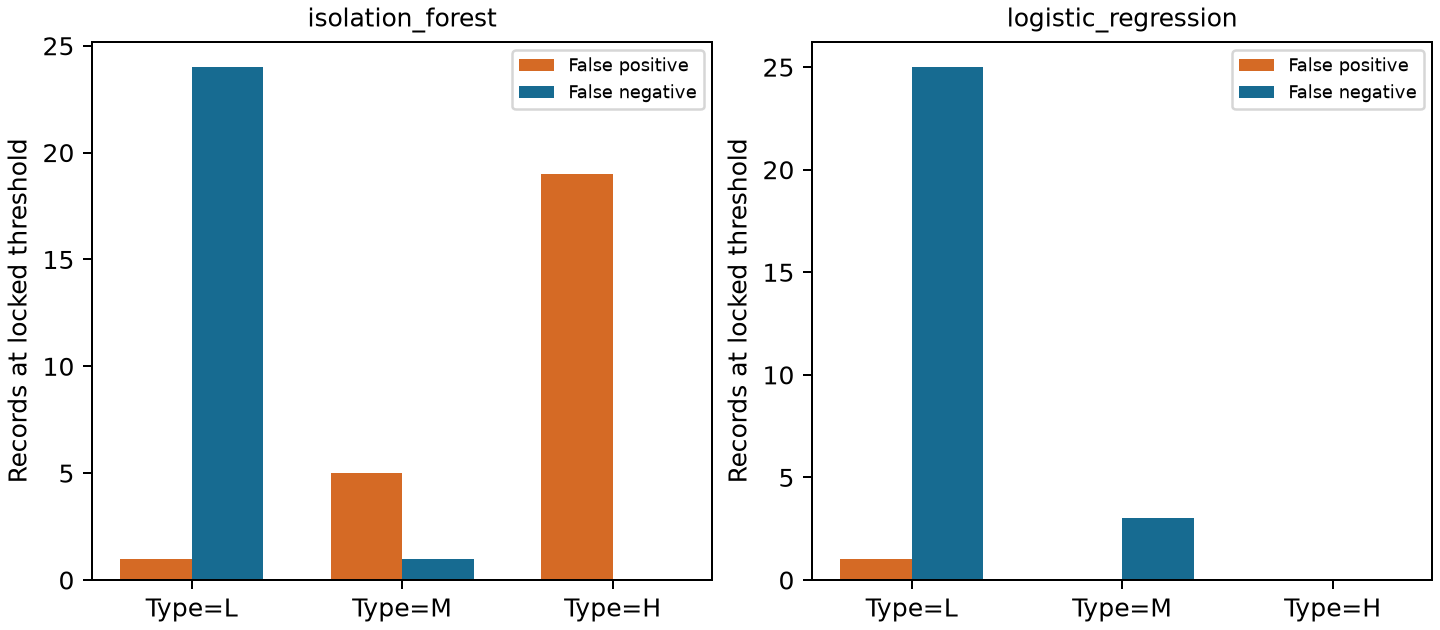

,model_family,split_id,feature_set,candidate_id,validation_ap,validation_precision_at_50
0,isolation_forest,ordered-gap100-v1,base,if-base-m1024,0.161526,0.14
1,isolation_forest,ordered-gap100-v1,physical,if-physical-m1024,0.320247,0.30
2,isolation_forest,stratified-seed42-v1,base,if-base-m1024,0.140648,0.18
3,isolation_forest,stratified-seed42-v1,physical,if-physical-m1024,0.258498,0.40
4,logistic_regression,ordered-gap100-v1,base,lr-base-C0.01-none,0.501111,0.50
5,logistic_regression,ordered-gap100-v1,physical,lr-physical-C0.1-none,0.399199,0.36
6,logistic_regression,stratified-seed42-v1,base,lr-base-C10-none,0.432097,0.50
7,logistic_regression,stratified-seed42-v1,physical,lr-physical-C1-none,0.463414,0.52


In [5]:
from IPython.display import display, Image
for name in build_review_figures(ROOT):
    display(Image(filename=str(ROOT/'reports/figures/review'/name)))
pd.read_csv(ROOT/'reports/tables/review/validation-feature-comparison.csv')

## Giới hạn
Audit độc lập về mã tính chỉ số, không phải dữ liệu test độc lập mới. Checkout tái lập dùng cùng môi trường đã cài; chưa kiểm tra hệ điều hành/môi trường mới hoặc Docker. Giữ nguyên khóa v1; các phương án cải tiến mới cần giao thức kiểm chứng mới.